# Challenge 3: Can you change the correlation?

## 1. Problem Statement & Prediction
- **Original Circuit**: Prepares the standard Bell state $\vert{}\Phi^+\rangle = \frac{\vert{}00\rangle + \vert{}11\rangle}{\sqrt{2}}$. In this state, the two qubits are strongly correlated; measurement outcomes will predominantly be `00` and `11` with approximately equal probabilities.
- **Modification**: We take the Bell circuit and apply exactly **one** additional single-qubit gate: a Pauli-$X$ gate on qubit 1 immediately after the CNOT gate ($CNOT_{01}$). This transforms the state into $\vert{}\Psi^+\rangle = \frac{\vert{}01\rangle + \vert{}10\rangle}{\sqrt{2}}$.
- **Prediction**: Adding the $X$ gate inverts the correlation into an **anti-correlation**. Measurements on a real IBM Quantum processor will show `01` and `10` dominating (roughly 50% each), while `00` and `11` will be suppressed to near zero (accounting for minor quantum hardware noise).

In [1]:
# Cell 2: Import libraries and initialize IBM Quantum Runtime Service
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Initialize service using your saved account / instance
service = QiskitRuntimeService()

# Select the least-busy real quantum computer
backend = service.least_busy(operational=True, simulator=False)
print(f"Connected to IBM Quantum backend: {backend.name}")

Connected to IBM Quantum backend: ibm_fez


## 2. Circuit Construction
We construct both circuits within the design constraints:
- Exactly 2 qubits.
- Both qubits measured.
- Original Bell state uses 2 gates ($H$, $CX$).
- Modified circuit adds 1 gate ($X$), totaling 3 gates (strictly $\le 4$ quantum gates before measurement).

Original Circuit:


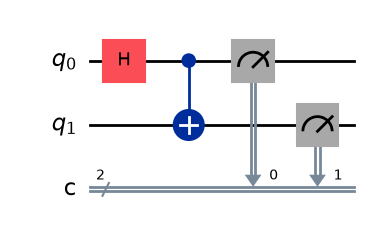

In [2]:
# Cell 4: Construct Original Bell-State Circuit (|Phi+>)
qc_original = QuantumCircuit(2, 2)
qc_original.h(0)
qc_original.cx(0, 1)
qc_original.measure([0, 1], [0, 1])

print("Original Circuit:")
display(qc_original.draw('mpl'))

Modified Circuit:


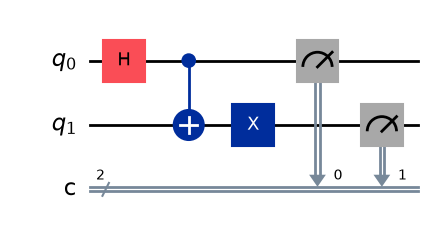

In [3]:
# Cell 5: Construct Modified Circuit (|Psi+>)
qc_modified = QuantumCircuit(2, 2)
qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.x(1)  # Exactly one gate added to flip the correlation
qc_modified.measure([0, 1], [0, 1])

print("Modified Circuit:")
display(qc_modified.draw('mpl'))

## 3. Transpilation & Execution on IBM Quantum Hardware
Transpiling the circuits into ISA (Instruction Set Architecture) circuits compatible with the target IBM quantum backend and executing for **100 shots** using `SamplerV2`.

In [5]:
# Cell 7: Transpile circuits to backend target (ISA)
pm = generate_preset_pass_manager(target=backend.target, optimization_level=3)
qc_orig_isa = pm.run(qc_original)
qc_mod_isa = pm.run(qc_modified)

print("Circuits transpiled successfully for hardware execution.")

Circuits transpiled successfully for hardware execution.


In [8]:
# Cell 8: Execute on real hardware with 100 shots
sampler = Sampler(mode=backend)
shots = 100

# Submit both circuits together in a single job
print("Submitting job to IBM Quantum hardware...")
job = sampler.run([qc_orig_isa, qc_mod_isa], shots=shots)
print(f"Job ID: {job.job_id()}")
print("Waiting for job to complete on hardware queue...")

result = job.result()


C:\Users\surya\AppData\Local\Temp\ipykernel_15032\3012601314.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitting job to IBM Quantum hardware...
Job ID: db5p1rg4qg6s73c3pts0
Waiting for job to complete on hardware queue...


In [9]:
# Extract measurement counts from the classical register ('c')
counts_original = result[0].data.c.get_counts()
counts_modified = result[1].data.c.get_counts()

print(f"Original Circuit Counts (100 shots): {counts_original}")
print(f"Modified Circuit Counts (100 shots): {counts_modified}")

Original Circuit Counts (100 shots): {'11': 56, '00': 44}
Modified Circuit Counts (100 shots): {'01': 45, '10': 53, '00': 2}


## 4. Measurement Results & Histogram Comparison
Comparing the distribution of measurement counts between both circuits.

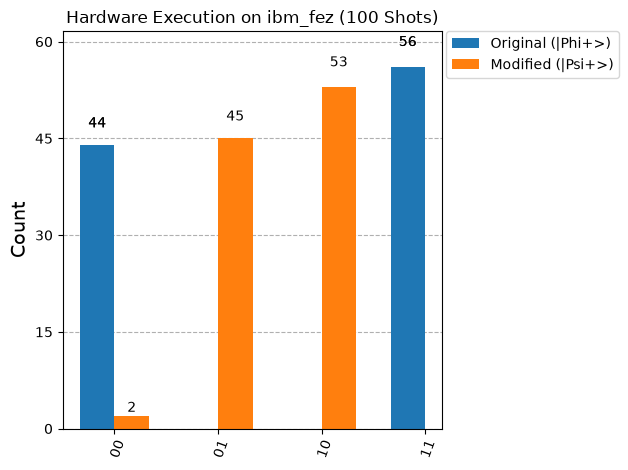

In [10]:
# Cell 10: Display side-by-side histogram
plot_histogram(
    [counts_original, counts_modified],
    legend=['Original (|Phi+>)', 'Modified (|Psi+>)'],
    title=f"Hardware Execution on {backend.name} (100 Shots)"
)

## 5. Explanation of Observed Change
- **Constraint Verification**: The circuit uses 2 qubits, 3 quantum gates prior to measurement (below the 4-gate limit), measures both qubits, and was executed on IBM Quantum hardware for 100 shots.
- **Observed Behavior on Hardware**:
  - The **original circuit** produced measurements dominated by `00` and `11`, verifying that qubit 0 and qubit 1 were strongly **correlated** (yielding identical values).
  - The **modified circuit** produced measurements dominated by `01` and `10`, demonstrating that the outcomes are now strongly **anti-correlated** (yielding opposite values). Any occasional `00` or `11` counts in the modified run are attributable to physical decoherence and readout errors on the QPU.
- **Physical Reason for the Change**: The added Pauli-$X$ gate performs a bit-flip on qubit 1 ($\vert{}0\rangle \leftrightarrow \vert{}1\rangle$). This maps the entangled state from $\vert{}\Phi^+\rangle = \frac{\vert{}00\rangle + \vert{}11\rangle}{\sqrt{2}}$ to $\vert{}\Psi^+\rangle = \frac{\vert{}01\rangle + \vert{}10\rangle}{\sqrt{2}}$, which swaps the parity and changes the correlation from parallel to antiparallel while preserving maximum entanglement.